# E-Commerce Shipping

**Team:** THE ETERNAL FLAME

Department of Artificial Intelligence and Data Science (B.Tech.)

Panimalar Engineering College, Chennai, India

| Member | Roll number | Registration number |
|---|---|---|
| SAMARUBAN V | 2025PECAI735 | 2114252430558 |
| YUVARAJ K | 2025PECAI855 | 2114252430755 |
| DINESHWARA M | 2025PECAI507 | 2114252430133 |
| ROHITH KUMAR S | 2025PECAI712 | 2114252430524 |
| KATHIR S | 2025PECAI590 | 2114252430281 |


## Phase 1 — Check and prepare the data

We load the CSV and check its size, columns, missing values, duplicates, and valid ranges. If the data is already complete, there is no reason to drop rows or fill values.

### Run this notebook
Keep `Train.csv` in the same folder. Install the packages listed in `requirements.txt`, open the notebook in Jupyter, then restart the kernel and run all cells in order. The public dataset source and setup steps are in `README.md`.

In [1]:
# Packages used below

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

In [2]:
# Load the CSV

df = pd.read_csv("Train.csv")

In [3]:
df.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [4]:
print("Rows and columns:", df.shape)
print("\nData types:")
print(df.dtypes)

Rows and columns: (10999, 12)

Data types:
ID                     int64
Warehouse_block          str
Mode_of_Shipment         str
Customer_care_calls    int64
Customer_rating        int64
Cost_of_the_Product    int64
Prior_purchases        int64
Product_importance       str
Gender                   str
Discount_offered       int64
Weight_in_gms          int64
Reached.on.Time_Y.N    int64
dtype: object


In [5]:
print("\nMissing values:")
print(df.isna().sum())


Missing values:
ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64


In [6]:

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())


Duplicate rows: 0
Duplicate IDs: 0


In [7]:
for column in ["Warehouse_block", "Mode_of_Shipment",
               "Product_importance", "Gender", "Reached.on.Time_Y.N"]:
    print(df[column].value_counts())

Warehouse_block
F    3666
D    1834
A    1833
B    1833
C    1833
Name: count, dtype: int64
Mode_of_Shipment
Ship      7462
Flight    1777
Road      1760
Name: count, dtype: int64
Product_importance
low       5297
medium    4754
high       948
Name: count, dtype: int64
Gender
F    5545
M    5454
Name: count, dtype: int64
Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64


In [8]:
columns = ["Customer_care_calls", "Customer_rating",
           "Cost_of_the_Product", "Prior_purchases",
           "Discount_offered", "Weight_in_gms"]

df[columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0


In [9]:
df_clean = df.copy()

df_clean = df_clean.rename(columns={"Reached.on.Time_Y.N": "Delayed"})

df_clean.columns

Index(['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls',
       'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases',
       'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms',
       'Delayed'],
      dtype='str')

In [10]:
print("Invalid delivery values:", (~df_clean["Delayed"].isin([0, 1])).sum())
print("Ratings outside 1 to 5:", (~df_clean["Customer_rating"].between(1, 5)).sum())

print("Costs at or below zero:", (df_clean["Cost_of_the_Product"] <= 0).sum())
print("Weights at or below zero:", (df_clean["Weight_in_gms"] <= 0).sum())
print("Negative discounts:", (df_clean["Discount_offered"] < 0).sum())
print("Negative care calls:", (df_clean["Customer_care_calls"] < 0).sum())
print("Negative prior purchases:", (df_clean["Prior_purchases"] < 0).sum())

Invalid delivery values: 0
Ratings outside 1 to 5: 0
Costs at or below zero: 0
Weights at or below zero: 0
Negative discounts: 0
Negative care calls: 0
Negative prior purchases: 0


### Data quality result

The file has 10,999 rows. Our checks found no missing values, duplicate rows, duplicate IDs, or invalid values in the fields tested, so we kept every shipment.

`df` holds the original table. `df_clean` is a copy with `Reached.on.Time_Y.N` renamed to `Delayed`. In this dataset, 1 means late and 0 means on time. `ID` is a record label; we do not use it to explain delays.

## Phase 2 — Understand the fields and choose questions

Each row is one shipment. `Delayed` is the result we want to study.

| Topic | Fields | Question |
|---|---|---|
| Shipping | Warehouse block, shipment mode | Is one group late more often? |
| Customer | Care calls, rating, prior purchases | Do customer groups have different results? |
| Product and order | Cost, importance, discount, weight | Which kinds of orders are late more often? |

We check gender once, then focus on the shipping, customer, and order fields. The next cells confirm that these fields have data we can compare and give us the overall late rate.

In [11]:
# Check the fields for our questions
analysis_fields = [
    "Warehouse_block", "Mode_of_Shipment",
    "Customer_care_calls", "Customer_rating", "Prior_purchases",
    "Cost_of_the_Product", "Product_importance",
    "Discount_offered", "Weight_in_gms", "Delayed"
]

field_summary = pd.DataFrame({
    "Data type": df_clean[analysis_fields].dtypes.astype(str),
    "Different values": df_clean[analysis_fields].nunique(),
    "Missing values": df_clean[analysis_fields].isna().sum()
})

print("Shipments:", len(df_clean))
print("Fields to investigate:", len(analysis_fields) - 1)
print("Delivery result: Delayed")
display(field_summary)

Shipments: 10999
Fields to investigate: 9
Delivery result: Delayed


,Data type,Different values,Missing values
Warehouse_block,str,5,0
Mode_of_Shipment,str,3,0
Customer_care_calls,int64,6,0
Customer_rating,int64,5,0
Prior_purchases,int64,8,0
Cost_of_the_Product,int64,215,0
Product_importance,str,3,0
Discount_offered,int64,65,0
Weight_in_gms,int64,4034,0
Delayed,int64,2,0


In [12]:
# Count late and on-time shipments
late_count = df_clean["Delayed"].sum()
total_count = len(df_clean)
on_time_count = total_count - late_count
late_rate = late_count / total_count * 100

print("Total shipments:", total_count)
print("Late shipments:", late_count)
print("On-time shipments:", on_time_count)
print("Late-delivery rate:", round(late_rate, 2), "%")

Total shipments: 10999
Late shipments: 6563
On-time shipments: 4436
Late-delivery rate: 59.67 %


Share of shipments by result:
Delayed
0    40.33
1    59.67
Name: count, dtype: float64


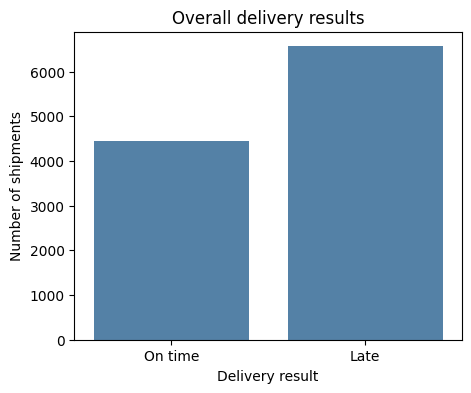

In [13]:
delivery_counts = df_clean["Delayed"].value_counts().sort_index()
print("Share of shipments by result:")
print((delivery_counts / total_count * 100).round(2))

plt.figure(figsize=(5, 4))
sns.barplot(x=["On time", "Late"], y=delivery_counts.values, color="steelblue")
plt.ylabel("Number of shipments")
plt.xlabel("Delivery result")
plt.title("Overall delivery results")
plt.show()

In [14]:
# Quick gender check
gender_table = pd.crosstab(df_clean["Gender"], df_clean["Delayed"])
gender_rate = gender_table[1] / gender_table.sum(axis=1) * 100
chi2, gender_p, dof, expected = stats.chi2_contingency(gender_table)

print(gender_table)
print("\nLate rate by gender (%):")
print(gender_rate.round(2))
print("Chi-square p-value:", round(gender_p, 4))

Delayed     0     1
Gender             
F        2249  3296
M        2187  3267

Late rate by gender (%):
Gender
F    59.44
M    59.90
dtype: float64
Chi-square p-value: 0.6367


### Phase 2 checkpoint

We can use all 10,999 shipments. There are 6,563 late shipments, so the starting late rate is 59.67%. Gender has similar late rates for F and M (59.44% and 59.90%; p = 0.637), so it is not a main question here.

The file has no delivery dates, call reasons, or later customer orders. We can compare groups, but those missing details limit what we can explain.

## Compare Shipment Modes and Warehouses

We compare the number of shipments and the late rate for Flight, Road, Ship, and each warehouse block. The charts show the rates; chi-square tests check whether the group differences are clear.

                  Shipments  Late rate
Mode_of_Shipment                      
Flight                 1777      60.16
Road                   1760      58.81
Ship                   7462      59.76


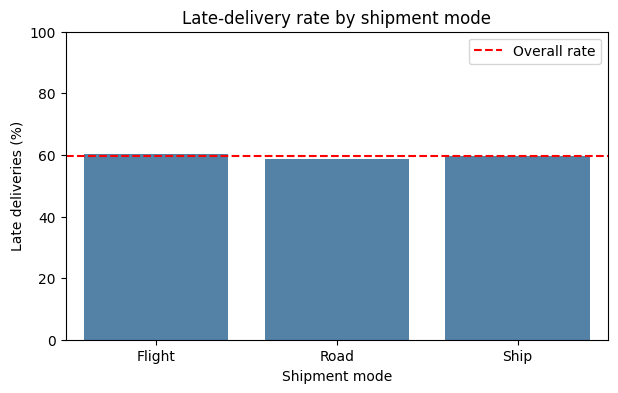

In [15]:

mode_summary = df_clean.groupby("Mode_of_Shipment")["Delayed"].agg(["count", "mean"])
mode_summary.columns = ["Shipments", "Late rate"]
mode_summary["Late rate"] = mode_summary["Late rate"] * 100

print(mode_summary.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(x=mode_summary.index, y=mode_summary["Late rate"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.ylabel("Late deliveries (%)")
plt.xlabel("Shipment mode")
plt.title("Late-delivery rate by shipment mode")
plt.ylim(0, 100)
plt.legend()
plt.show()

In [16]:
mode_table = pd.crosstab(df_clean["Mode_of_Shipment"], df_clean["Delayed"])
print(mode_table)

chi2, p_value, dof, expected = stats.chi2_contingency(mode_table)

print("\nChi-square value:", round(chi2, 2))
print("p-value:", round(p_value, 4))

Delayed              0     1
Mode_of_Shipment            
Flight             708  1069
Road               725  1035
Ship              3003  4459

Chi-square value: 0.74
p-value: 0.6895


                 Shipments  Late rate
Warehouse_block                      
A                     1833      58.65
B                     1833      60.23
C                     1833      59.68
D                     1834      59.76
F                     3666      59.85


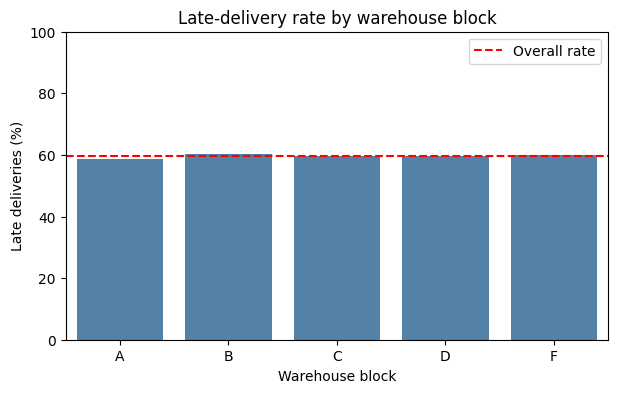

In [17]:
# Compare warehouse blocks in the same way
block_summary = df_clean.groupby("Warehouse_block")["Delayed"].agg(["count", "mean"])
block_summary.columns = ["Shipments", "Late rate"]
block_summary["Late rate"] = block_summary["Late rate"] * 100

print(block_summary.round(2))

plt.figure(figsize=(7, 4))
sns.barplot(x=block_summary.index, y=block_summary["Late rate"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.ylabel("Late deliveries (%)")
plt.xlabel("Warehouse block")
plt.title("Late-delivery rate by warehouse block")
plt.ylim(0, 100)
plt.legend()
plt.show()

In [18]:
block_table = pd.crosstab(df_clean["Warehouse_block"], df_clean["Delayed"])
print(block_table)

chi2, p_value, dof, expected = stats.chi2_contingency(block_table)

print("\nChi-square value:", round(chi2, 2))
print("p-value:", round(p_value, 4))

Delayed             0     1
Warehouse_block            
A                 758  1075
B                 729  1104
C                 739  1094
D                 738  1096
F                1472  2194

Chi-square value: 1.09
p-value: 0.896


### Mode and warehouse together

We also check each mode-and-warehouse pair. A problem in one pair might be hidden when we look at modes and warehouses separately. The table shows the number of orders behind each heatmap value.

Shipments  Late shipments  Late rate (%)
Mode_of_Shipment Warehouse_block                                          
Flight           A                      297             174          58.59
                 B                      296             177          59.80
                 C                      295             184          62.37
                 D                      297             178          59.93
                 F                      592             356          60.14
Road             A                      294             168          57.14
                 B                      294             172          58.50
                 C                      294             169          57.48
                 D                      292             174          59.59
                 F                      586             352          60.07
Ship             A                     1242             733          59.02
                 B                     1243             755          60.74
                 C                     1244             741          59.57
                 D                     1245             744          59.76
                 F                     2488            1486          59.73

Chi-square p-value: 0.9978
Cramer's V: 0.018


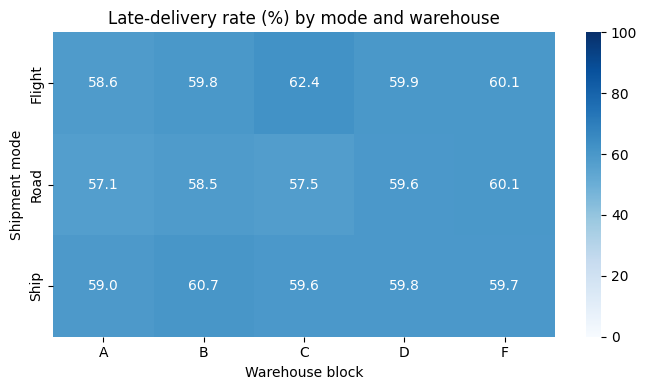

In [19]:
mode_block_summary = df_clean.groupby(
    ["Mode_of_Shipment", "Warehouse_block"]
)["Delayed"].agg(["count", "sum", "mean"])
mode_block_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
mode_block_summary["Late rate (%)"] *= 100
display(mode_block_summary.round(2))

combined_group = df_clean["Mode_of_Shipment"] + " / " + df_clean["Warehouse_block"]
combined_table = pd.crosstab(combined_group, df_clean["Delayed"])
combined_chi2, combined_p, _, _ = stats.chi2_contingency(combined_table)
combined_v = np.sqrt(combined_chi2 / len(df_clean))
print("Chi-square p-value:", round(combined_p, 4))
print("Cramer's V:", round(combined_v, 3))

mode_block_rates = mode_block_summary["Late rate (%)"].unstack("Warehouse_block")
plt.figure(figsize=(7, 4))
sns.heatmap(mode_block_rates, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100)
plt.xlabel("Warehouse block")
plt.ylabel("Shipment mode")
plt.title("Late-delivery rate (%) by mode and warehouse")
plt.tight_layout()
plt.show()

All 15 pairs have at least 292 shipments. Their late rates are close, and the combined test is not significant (p = 0.998; Cramer's V = 0.018). We do not see one shipping pair that deserves special attention from this data.

## Customer Experience and Purchase History

We check care calls, ratings, and prior purchases one at a time. Each table includes group size and late rate, followed by a chart and a chi-square test. We also report Cramer's V because a small p-value can come from a large dataset even when the difference is small.

The file does not say when calls or ratings happened. Prior purchases are from before this shipment, so they cannot tell us whether a customer bought again afterward.

In [20]:
# Average customer values by delivery result
customer_fields = ["Customer_care_calls", "Customer_rating", "Prior_purchases"]
customer_averages = df_clean.groupby("Delayed")[customer_fields].agg(["mean", "median"])
print("0 = on time; 1 = late")
display(customer_averages.round(2))

0 = on time; 1 = late


Customer_care_calls        Customer_rating        Prior_purchases  \
                       mean median            mean median            mean   
Delayed                                                                     
0                      4.15    4.0            2.97    3.0            3.67   
1                      3.99    4.0            3.01    3.0            3.50   

                
        median  
Delayed         
0          3.0  
1          3.0

### Customer-care calls

Do the late rates change with the number of calls? We do not know what the calls were about or when they happened.

,Shipments,Late shipments,Late rate (%)
Customer_care_calls,,,
2,638,416,65.20
3,3217,2011,62.51
4,3557,2126,59.77
5,2328,1360,58.42
6,1013,523,51.63
7,246,127,51.63


Chi-square p-value: 1.84e-10
Cramer's V: 0.07


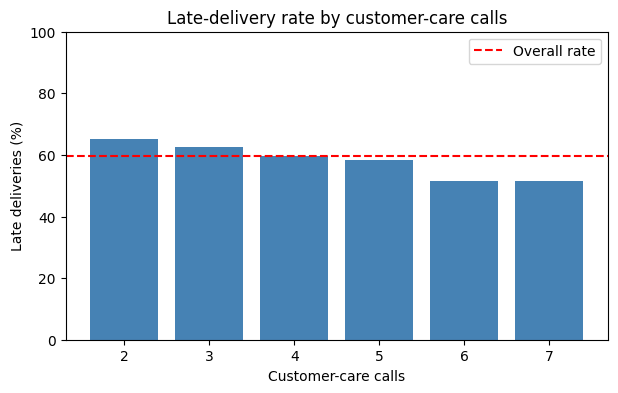

In [21]:
calls_summary = df_clean.groupby("Customer_care_calls")["Delayed"].agg(["count", "sum", "mean"])
calls_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
calls_summary["Late rate (%)"] *= 100
display(calls_summary.round(2))

calls_table = pd.crosstab(df_clean["Customer_care_calls"], df_clean["Delayed"])
calls_chi2, calls_p, _, _ = stats.chi2_contingency(calls_table)
calls_v = np.sqrt(calls_chi2 / len(df_clean))
print("Chi-square p-value:", f"{calls_p:.3g}")
print("Cramer's V:", round(calls_v, 3))

plt.figure(figsize=(7, 4))
plt.bar(calls_summary.index.astype(str), calls_summary["Late rate (%)"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Customer-care calls")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by customer-care calls")
plt.ylim(0, 100)
plt.legend()
plt.show()

### Customer rating

Do late shipments have different ratings? We compare all five rating levels and check their group sizes.

,Shipments,Late shipments,Late rate (%)
Customer_rating,,,
1,2235,1313,58.75
2,2165,1273,58.80
3,2239,1357,60.61
4,2189,1303,59.52
5,2171,1317,60.66


Chi-square p-value: 0.525
Cramer's V: 0.017


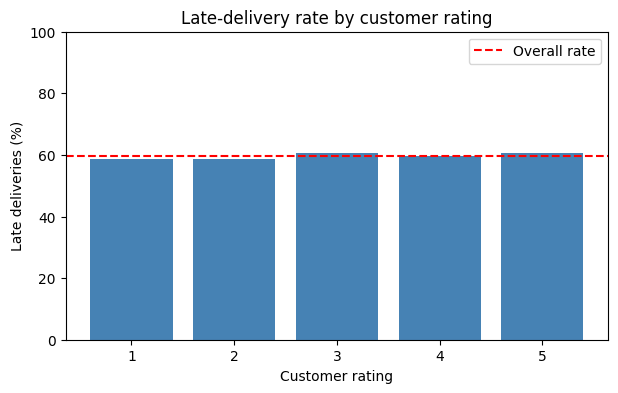

In [22]:
rating_summary = df_clean.groupby("Customer_rating")["Delayed"].agg(["count", "sum", "mean"])
rating_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
rating_summary["Late rate (%)"] *= 100
display(rating_summary.round(2))

rating_table = pd.crosstab(df_clean["Customer_rating"], df_clean["Delayed"])
rating_chi2, rating_p, _, _ = stats.chi2_contingency(rating_table)
rating_v = np.sqrt(rating_chi2 / len(df_clean))
print("Chi-square p-value:", f"{rating_p:.3g}")
print("Cramer's V:", round(rating_v, 3))

plt.figure(figsize=(7, 4))
plt.bar(rating_summary.index.astype(str), rating_summary["Late rate (%)"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Customer rating")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by customer rating")
plt.ylim(0, 100)
plt.legend()
plt.show()

### Prior purchases

Do returning customers' orders have different late rates? Some purchase-count groups are small, so we check the counts before interpreting their rates.

,Shipments,Late shipments,Late rate (%)
Prior_purchases,,,
2,2599,1625,62.52
3,3955,2534,64.07
4,2155,1171,54.34
5,1287,642,49.88
6,561,314,55.97
7,136,92,67.65
8,128,83,64.84
10,178,102,57.30


Chi-square p-value: 4.46e-24
Cramer's V: 0.107


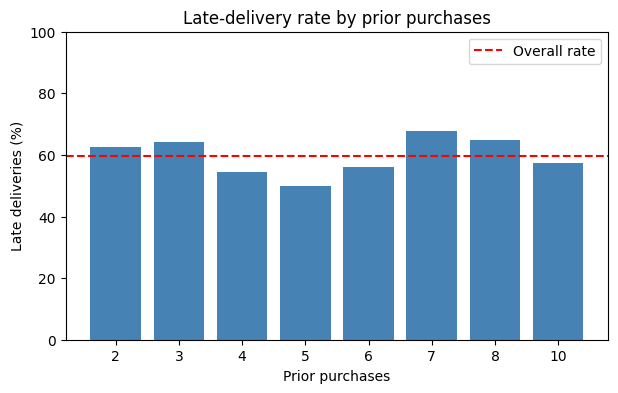

In [23]:
prior_summary = df_clean.groupby("Prior_purchases")["Delayed"].agg(["count", "sum", "mean"])
prior_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
prior_summary["Late rate (%)"] *= 100
display(prior_summary.round(2))

prior_table = pd.crosstab(df_clean["Prior_purchases"], df_clean["Delayed"])
prior_chi2, prior_p, _, _ = stats.chi2_contingency(prior_table)
prior_v = np.sqrt(prior_chi2 / len(df_clean))
print("Chi-square p-value:", f"{prior_p:.3g}")
print("Cramer's V:", round(prior_v, 3))

plt.figure(figsize=(7, 4))
plt.bar(prior_summary.index.astype(str), prior_summary["Late rate (%)"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Prior purchases")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by prior purchases")
plt.ylim(0, 100)
plt.legend()
plt.show()

### What the customer checks found

- **Care calls:** Rates differ across call-count groups, but the relationship is small (Cramer's V = 0.070). On-time shipments average 4.15 calls and late shipments 3.99. That does not mean calls make deliveries faster.
- **Ratings:** The rates are close across ratings 1 to 5 (p = 0.525). We found no clear rating pattern.
- **Prior purchases:** The groups differ, but the rate does not steadily rise or fall with purchase count. Some high-count groups have few orders.

We cannot use these fields to say why someone called or whether a delay changed later buying.

### Recheck customer patterns within discounts 1 to 10

Every order with a discount above 10 is marked late. We repeat the customer checks among discounts 1 to 10 to see whether the earlier differences still appear.

In [24]:
common_discount = df_clean[df_clean["Discount_offered"].between(1, 10)]
customer_check_rows = []

for field in ["Customer_care_calls", "Customer_rating", "Prior_purchases"]:
    print("\n" + field + " among discount values 1-10")
    group_summary = common_discount.groupby(field)["Delayed"].agg(["count", "sum", "mean"])
    group_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
    group_summary["Late rate (%)"] *= 100
    display(group_summary.round(2))

    for label, records in [("All shipments", df_clean), ("Discount 1-10", common_discount)]:
        table = pd.crosstab(records[field], records["Delayed"])
        chi2, p_value, _, _ = stats.chi2_contingency(table)
        customer_check_rows.append([
            field, label, len(records), p_value, np.sqrt(chi2 / len(records))
        ])

customer_check = pd.DataFrame(customer_check_rows, columns=[
    "Field", "Records", "Shipments", "p-value", "Cramer's V"
])
print("\nAssociation comparison:")
display(customer_check.round(4))


Customer_care_calls among discount values 1-10


,Shipments,Late shipments,Late rate (%)
Customer_care_calls,,,
2,413,191,46.25
3,2282,1076,47.15
4,2674,1243,46.48
5,1831,863,47.13
6,912,422,46.27
7,240,121,50.42



Customer_rating among discount values 1-10


,Shipments,Late shipments,Late rate (%)
Customer_rating,,,
1,1703,781,45.86
2,1621,729,44.97
3,1723,841,48.81
4,1670,784,46.95
5,1635,781,47.77



Prior_purchases among discount values 1-10


,Shipments,Late shipments,Late rate (%)
Prior_purchases,,,
2,1810,836,46.19
3,2801,1380,49.27
4,1806,822,45.51
5,1144,499,43.62
6,474,227,47.89
7,91,47,51.65
8,96,51,53.12
10,130,54,41.54



Association comparison:


,Field,Records,Shipments,p-value,Cramer's V
0,Customer_care_calls,All shipments,10999,0.0000,0.0702
1,Customer_care_calls,Discount 1-10,8352,0.8902,0.0142
2,Customer_rating,All shipments,10999,0.5249,0.0171
3,Customer_rating,Discount 1-10,8352,0.1862,0.0272
4,Prior_purchases,All shipments,10999,0.0000,0.1070
5,Prior_purchases,Discount 1-10,8352,0.0173,0.0451


Most customer patterns become weaker in the discount 1 to 10 group. Care calls show no clear difference (p = 0.890), and neither do ratings (p = 0.186). Prior purchases still vary a little (p = 0.017), but the relationship is tiny (Cramer's V = 0.045). This is not enough to make a customer-retention claim.

## Product and Order Patterns

Next we compare cost, importance, discount, and weight. Each table shows how many orders were in a group, how many were late, and the late rate. Cost and weight have many values, so we split each into four groups of roughly equal size.

### Product cost

Do low- and high-cost orders have different late rates? Product cost is not the same as profit or the cost of a delay.

Cost boundaries:
0.00     96.0
0.25    169.0
0.50    214.0
0.75    251.0
1.00    310.0
Name: Cost_of_the_Product, dtype: float64


,Shipments,Late shipments,Late rate (%)
Cost_of_the_Product,,,
Q1 low,2751,1770,64.34
Q2,2757,1686,61.15
Q3,2796,1609,57.55
Q4 high,2695,1498,55.58


Chi-square p-value: 4.05e-11
Cramer's V: 0.068


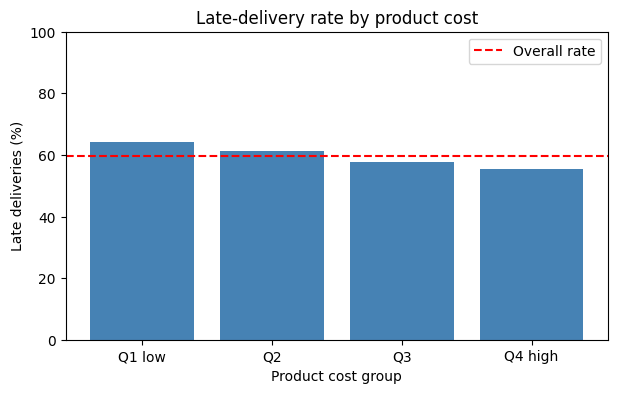

In [25]:
cost_quartile = pd.qcut(
    df_clean["Cost_of_the_Product"], 4,
    labels=["Q1 low", "Q2", "Q3", "Q4 high"]
)
cost_summary = df_clean.groupby(cost_quartile, observed=True)["Delayed"].agg(["count", "sum", "mean"])
cost_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
cost_summary["Late rate (%)"] *= 100
print("Cost boundaries:")
print(df_clean["Cost_of_the_Product"].quantile([0, 0.25, 0.5, 0.75, 1]))
display(cost_summary.round(2))

cost_chi2, cost_p, _, _ = stats.chi2_contingency(pd.crosstab(cost_quartile, df_clean["Delayed"]))
cost_v = np.sqrt(cost_chi2 / len(df_clean))
print("Chi-square p-value:", f"{cost_p:.3g}")
print("Cramer's V:", round(cost_v, 3))

plt.figure(figsize=(7, 4))
plt.bar(cost_summary.index.astype(str), cost_summary["Late rate (%)"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Product cost group")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by product cost")
plt.ylim(0, 100)
plt.legend()
plt.show()

### Product importance

We compare low, medium, and high importance. The number of late orders matters as well as the rate.

,Shipments,Late shipments,Late rate
Product_importance,,,
low,5297,3140,59.28
medium,4754,2807,59.05
high,948,616,64.98


Chi-square p-value: 0.00223
Cramer's V: 0.033
High minus low: 5.7 percentage points


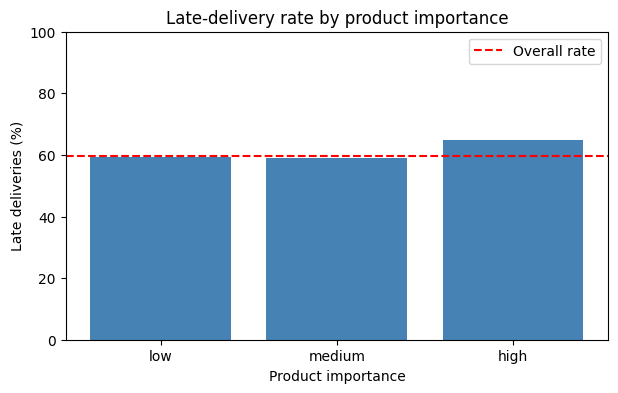

In [26]:
importance_summary = df_clean.groupby("Product_importance")["Delayed"].agg(["count", "sum", "mean"])
importance_summary.columns = ["Shipments", "Late shipments", "Late rate"]
importance_summary["Late rate"] *= 100
importance_summary = importance_summary.loc[["low", "medium", "high"]]
display(importance_summary.round(2))

importance_table = pd.crosstab(df_clean["Product_importance"], df_clean["Delayed"])
importance_chi2, importance_p, _, _ = stats.chi2_contingency(importance_table)
importance_v = np.sqrt(importance_chi2 / len(df_clean))
high_rate = importance_summary.loc["high", "Late rate"]
low_rate = importance_summary.loc["low", "Late rate"]
print("Chi-square p-value:", f"{importance_p:.3g}")
print("Cramer's V:", round(importance_v, 3))
print("High minus low:", round(high_rate - low_rate, 2), "percentage points")

plt.figure(figsize=(7, 4))
plt.bar(importance_summary.index, importance_summary["Late rate"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Product importance")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by product importance")
plt.ylim(0, 100)
plt.legend()
plt.show()

### Discount offered

We check the sharp split above 10, then compare values 1 to 10 with one another. A discount pattern does not show that discounts caused delays.

,Shipments,Late shipments,Late rate (%)
Discount 1-10,8352,3916,46.89
Discount above 10,2647,2647,100.00


Chi-square p-value: < 0.001
Cramer's V: 0.463


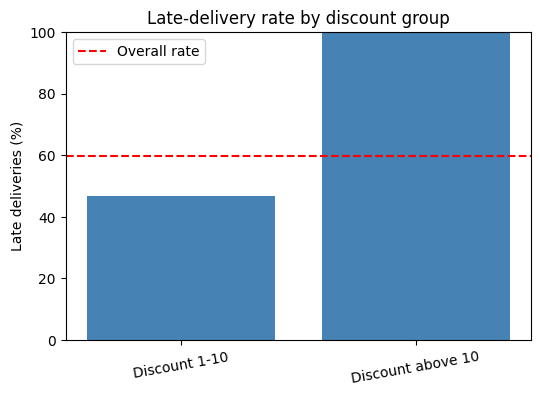

In [27]:
above_10 = df_clean["Discount_offered"] > 10
discount_table = pd.crosstab(above_10, df_clean["Delayed"])
discount_table.index = ["Discount 1-10", "Discount above 10"]
discount_summary = pd.DataFrame({
    "Shipments": discount_table.sum(axis=1),
    "Late shipments": discount_table[1]
})
discount_summary["Late rate (%)"] = (
    discount_summary["Late shipments"] / discount_summary["Shipments"] * 100
)
display(discount_summary.round(2))

discount_chi2, discount_p, _, _ = stats.chi2_contingency(discount_table)
discount_v = np.sqrt(discount_chi2 / len(df_clean))
print("Chi-square p-value:", "< 0.001" if discount_p < 0.001 else round(discount_p, 4))
print("Cramer's V:", round(discount_v, 3))

plt.figure(figsize=(6, 4))
plt.bar(discount_summary.index, discount_summary["Late rate (%)"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by discount group")
plt.ylim(0, 100)
plt.xticks(rotation=10)
plt.legend()
plt.show()

### Shipment weight

We compare four weight groups. This can show a pattern that the overall average hides.

Weight boundaries (grams):
0.00    1001.0
0.25    1839.5
0.50    4149.0
0.75    5050.0
1.00    7846.0
Name: Weight_in_gms, dtype: float64


,Shipments,Late shipments,Late rate (%)
Weight_in_gms,,,
Q1 light,2750,1865,67.82
Q2,2751,2353,85.53
Q3,2749,1167,42.45
Q4 heavy,2749,1178,42.85


Chi-square p-value: < 0.001
Cramer's V: 0.37


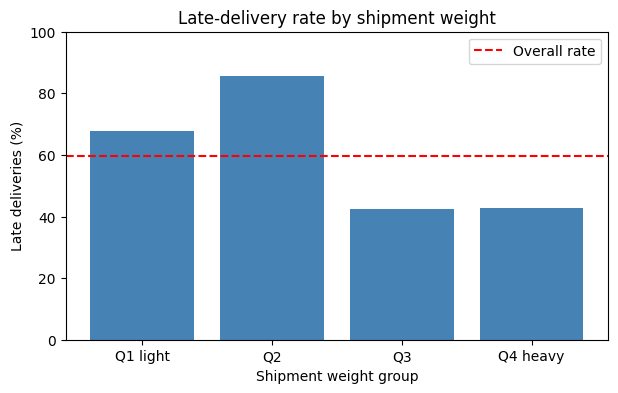

In [28]:
weight_quartile = pd.qcut(
    df_clean["Weight_in_gms"], 4,
    labels=["Q1 light", "Q2", "Q3", "Q4 heavy"]
)
weight_summary = df_clean.groupby(weight_quartile, observed=True)["Delayed"].agg(["count", "sum", "mean"])
weight_summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
weight_summary["Late rate (%)"] *= 100
print("Weight boundaries (grams):")
print(df_clean["Weight_in_gms"].quantile([0, 0.25, 0.5, 0.75, 1]))
display(weight_summary.round(2))

weight_chi2, weight_p, _, _ = stats.chi2_contingency(pd.crosstab(weight_quartile, df_clean["Delayed"]))
weight_v = np.sqrt(weight_chi2 / len(df_clean))
print("Chi-square p-value:", "< 0.001" if weight_p < 0.001 else round(weight_p, 4))
print("Cramer's V:", round(weight_v, 3))

plt.figure(figsize=(7, 4))
plt.bar(weight_summary.index.astype(str), weight_summary["Late rate (%)"], color="steelblue")
plt.axhline(late_rate, color="red", linestyle="--", label="Overall rate")
plt.xlabel("Shipment weight group")
plt.ylabel("Late deliveries (%)")
plt.title("Late-delivery rate by shipment weight")
plt.ylim(0, 100)
plt.legend()
plt.show()

### Compare within discounts 1 to 10

Because every discount above 10 is paired with a late label, we recheck cost, importance, and weight among discounts 1 to 10. This tells us which differences remain when we leave that unusual group aside.

In [29]:
discount_1_10 = df_clean["Discount_offered"].between(1, 10)
similar_orders = df_clean.loc[discount_1_10]
print("Shipments with discount 1-10:", len(similar_orders))
print("Their late rate:", round(similar_orders["Delayed"].mean() * 100, 2), "%")

small_discount_table = pd.crosstab(similar_orders["Discount_offered"], similar_orders["Delayed"])
small_chi2, small_p, _, _ = stats.chi2_contingency(small_discount_table)
print("Do discount values 1-10 differ? p-value:", round(small_p, 4))

for name, group in [
    ("Product importance", df_clean["Product_importance"]),
    ("Product cost group", cost_quartile),
    ("Shipment weight group", weight_quartile)
]:
    selected_group = group.loc[discount_1_10]
    summary = similar_orders.groupby(selected_group, observed=True)["Delayed"].agg(["count", "sum", "mean"])
    summary.columns = ["Shipments", "Late shipments", "Late rate (%)"]
    summary["Late rate (%)"] *= 100
    chi2, p_value, _, _ = stats.chi2_contingency(pd.crosstab(selected_group, similar_orders["Delayed"]))
    association = np.sqrt(chi2 / len(similar_orders))
    print("\n" + name)
    display(summary.round(2))
    print("p-value:", f"{p_value:.3g}", "| Cramer's V:", round(association, 3))

Shipments with discount 1-10: 8352
Their late rate: 46.89 %
Do discount values 1-10 differ? p-value: 0.7824

Product importance


,Shipments,Late shipments,Late rate (%)
Product_importance,,,
high,677,345,50.96
low,4073,1916,47.04
medium,3602,1655,45.95


p-value: 0.0543 | Cramer's V: 0.026

Product cost group


,Shipments,Late shipments,Late rate (%)
Cost_of_the_Product,,,
Q1 low,1861,880,47.29
Q2,1968,897,45.58
Q3,2239,1052,46.99
Q4 high,2284,1087,47.59


p-value: 0.586 | Cramer's V: 0.015

Shipment weight group


,Shipments,Late shipments,Late rate (%)
Weight_in_gms,,,
Q1 light,1798,913,50.78
Q2,1062,664,62.52
Q3,2749,1167,42.45
Q4 heavy,2743,1172,42.73


p-value: 1.35e-33 | Cramer's V: 0.137


### What the product checks found

- **Cost:** Low-cost orders look later in the full file, but the cost-group difference disappears among discounts 1 to 10 (p = 0.586).
- **Importance:** High-importance orders are 64.98% late in the full file. The difference is small and weaker among discounts 1 to 10 (p = 0.054).
- **Discount:** All 2,647 orders above 10 are marked late. Within 1 to 10, the rates are similar (p = 0.782). We should check how these records were created before treating discount as a business cause.
- **Weight:** Weight groups still differ among discounts 1 to 10, although the relationship is smaller than in the full file.

Weight is worth a closer look. None of these comparisons tells us that changing a product feature would prevent a delay.

### Weight groups within each shipment method

We check whether the weight pattern appears in Flight, Road, and Ship separately. The shipment counts help us judge each rate.

Shipments  Late shipments  Late rate (%)
Mode_of_Shipment Weight_in_gms                                          
Flight           Q1 light             285             142          49.82
                 Q2                   169             102          60.36
                 Q3                   480             213          44.38
                 Q4 heavy             410             179          43.66
Road             Q1 light             283             129          45.58
                 Q2                   174             117          67.24
                 Q3                   452             181          40.04
                 Q4 heavy             445             202          45.39
Ship             Q1 light            1230             642          52.20
                 Q2                   719             445          61.89
                 Q3                  1817             773          42.54
                 Q4 heavy            1888             791          41.90

Shipment counts behind the heatmap:


Weight_in_gms,Q1 light,Q2,Q3,Q4 heavy
Mode_of_Shipment,,,,
Flight,285,169,480,410
Road,283,174,452,445
Ship,1230,719,1817,1888


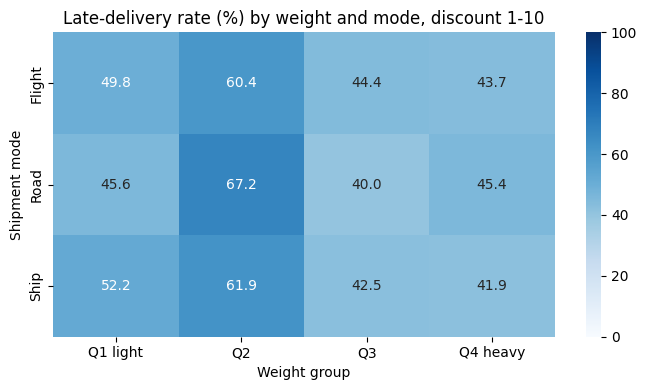

In [30]:
weight_by_mode = similar_orders.groupby(
    ["Mode_of_Shipment", weight_quartile.loc[discount_1_10]], observed=True
)["Delayed"].agg(["count", "sum", "mean"])
weight_by_mode.columns = ["Shipments", "Late shipments", "Late rate (%)"]
weight_by_mode["Late rate (%)"] *= 100
display(weight_by_mode.round(2))

rate_grid = weight_by_mode["Late rate (%)"].unstack()
count_grid = weight_by_mode["Shipments"].unstack()
print("Shipment counts behind the heatmap:")
display(count_grid)

plt.figure(figsize=(7, 4))
sns.heatmap(rate_grid, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100)
plt.xlabel("Weight group")
plt.ylabel("Shipment mode")
plt.title("Late-delivery rate (%) by weight and mode, discount 1-10")
plt.tight_layout()
plt.show()

Weight Q2 has a higher late rate than the heavier groups in all three methods: 60.4% for Flight, 67.2% for Road, and 61.9% for Ship. Those Q2 groups contain 169, 174, and 719 orders. We would need route, carrier, packing, and dispatch data to find out why.

## Compare Simple Warning Rules

We compare four possible ways to flag an order, using only the discount 1 to 10 group. Its starting late rate is 46.89%. For each rule, we count flagged orders, late orders found, and false alarms.

Two numbers matter: the **late rate among flagged orders** and the **share of all late orders found**. A rule can score well on one and poorly on the other. We picked these rules after studying this file, so these are retrospective results.

In [31]:
# Try four rules among discounts 1 to 10
normal_discount = df_clean["Discount_offered"].between(1, 10)
normal_orders = df_clean.loc[normal_discount]
normal_late = normal_orders["Delayed"].sum()
normal_rate = normal_orders["Delayed"].mean() * 100

light_cutoff = df_clean["Weight_in_gms"].quantile(0.25)
few_cutoff = df_clean["Prior_purchases"].median()
light_few = (df_clean["Weight_in_gms"] <= light_cutoff) & (df_clean["Prior_purchases"] <= few_cutoff)
simple_score = (
    (df_clean["Weight_in_gms"] <= light_cutoff).astype(int)
    + (df_clean["Prior_purchases"] <= few_cutoff).astype(int)
    + (df_clean["Product_importance"] == "high").astype(int)
)

candidate_groups = {
    "Light + few purchases": light_few,
    "Score 2 or 3": simple_score >= 2,
    "Weight Q2": weight_quartile == "Q2",
    "High importance": df_clean["Product_importance"] == "high"
}

results = []
for name, group in candidate_groups.items():
    chosen = group & normal_discount
    selected = chosen.sum()
    late_selected = df_clean.loc[chosen, "Delayed"].sum()
    late_rate_selected = late_selected / selected * 100
    results.append([
        name, selected, late_selected, selected - late_selected,
        late_rate_selected, late_rate_selected - normal_rate,
        late_selected / normal_late * 100
    ])

rule_summary = pd.DataFrame(results, columns=[
    "Group", "Flagged", "Late", "False alarms", "Late rate (%)",
    "Above baseline (points)", "Share of late orders found (%)"
]).sort_values("Late rate (%)", ascending=False)

print("Discount 1-10 shipments:", len(normal_orders))
print("Late shipments:", normal_late)
print("Starting late rate:", round(normal_rate, 2), "%")
print("Light weight is", light_cutoff, "g or less; few prior purchases is", few_cutoff, "or less")
display(rule_summary.round(2))

Discount 1-10 shipments: 8352
Late shipments: 3916
Starting late rate: 46.89 %
Light weight is 1839.5 g or less; few prior purchases is 3.0 or less


,Group,Flagged,Late,False alarms,Late rate (%),Above baseline (points),Share of late orders found (%)
0,Light + few purchases,200,165,35,82.50,35.61,4.21
2,Weight Q2,1062,664,398,62.52,15.64,16.96
1,Score 2 or 3,654,395,259,60.40,13.51,10.09
3,High importance,677,345,332,50.96,4.07,8.81


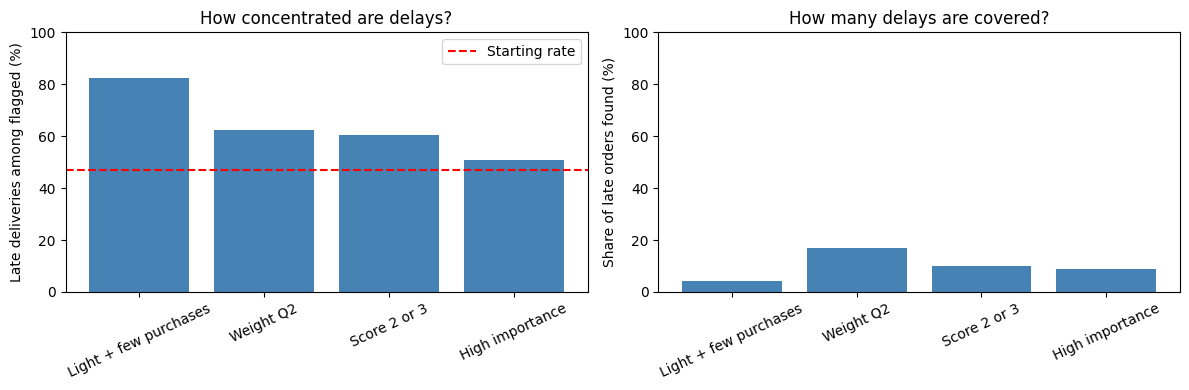

In [32]:
# Show both late rate and coverage
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(rule_summary["Group"], rule_summary["Late rate (%)"], color="steelblue")
axes[0].axhline(normal_rate, color="red", linestyle="--", label="Starting rate")
axes[0].set_ylabel("Late deliveries among flagged (%)")
axes[0].set_title("How concentrated are delays?")
axes[0].set_ylim(0, 100)
axes[0].legend()

axes[1].bar(rule_summary["Group"], rule_summary["Share of late orders found (%)"], color="steelblue")
axes[1].set_ylabel("Share of late orders found (%)")
axes[1].set_title("How many delays are covered?")
axes[1].set_ylim(0, 100)

for axis in axes:
    axis.tick_params(axis="x", labelrotation=25)
plt.tight_layout()
plt.show()

### What the rule comparison means

The light-weight/few-purchases rule flags only 200 orders: 165 were late (82.5%), but that is just 4.21% of the late orders in this comparison group. Weight Q2 flags 1,062 orders; 664 were late (62.52%), so it covers more delays but also raises 398 false alarms.

Which rule is useful would depend on how many orders a company can review, what that review costs, and whether it can actually prevent a delay. We have not tested either rule on future orders.

### Check the rules in two random halves

We repeat the same rule checks in two halves of the discount 1 to 10 records. This checks whether the result is roughly stable inside this file. It is not a future-order test: we chose the rules after looking at the dataset, and there are no dates.

In [33]:
random_order = np.random.default_rng(42).permutation(normal_orders.index.to_numpy())
midpoint = len(random_order) // 2
halves = {
    "First half": random_order[:midpoint],
    "Second half": random_order[midpoint:]
}
stability_rows = []

for half_name, row_indices in halves.items():
    half_data = df_clean.loc[row_indices]
    half_late = half_data["Delayed"].sum()
    half_rate = half_data["Delayed"].mean() * 100
    for rule_name, rule in candidate_groups.items():
        selected_indices = row_indices[rule.loc[row_indices].to_numpy()]
        selected_count = len(selected_indices)
        selected_late = df_clean.loc[selected_indices, "Delayed"].sum()
        stability_rows.append([
            half_name, rule_name, len(half_data), half_rate,
            selected_count, selected_late,
            selected_late / selected_count * 100,
            selected_late / half_late * 100
        ])

stability_table = pd.DataFrame(stability_rows, columns=[
    "Half", "Group", "Shipments in half", "Half late rate (%)",
    "Flagged", "Late flagged", "Flagged late rate (%)", "Share of half's delays found (%)"
])
display(stability_table.round(2))

,Half,Group,Shipments in half,Half late rate (%),Flagged,Late flagged,Flagged late rate (%),Share of half's delays found (%)
0,First half,Light + few purchases,4176,46.14,90,71,78.89,3.68
1,First half,Score 2 or 3,4176,46.14,327,177,54.13,9.19
2,First half,Weight Q2,4176,46.14,553,350,63.29,18.16
3,First half,High importance,4176,46.14,354,164,46.33,8.51
4,Second half,Light + few purchases,4176,47.63,110,94,85.45,4.73
5,Second half,Score 2 or 3,4176,47.63,327,218,66.67,10.96
6,Second half,Weight Q2,4176,47.63,509,314,61.69,15.79
7,Second half,High importance,4176,47.63,323,181,56.04,9.10


Weight Q2 is similar in the two halves (63.29% and 61.69% late). Light weight plus few purchases is higher (78.89% and 85.45%) but flags only 90 and 110 orders. The other rules move around more. We would keep testing these groups before using them for real orders.

## Check Correlations

We compare each numeric field's correlation with the late label in the full file and among discounts 1 to 10. This is a quick check for straight-line relationships. It can miss other patterns and does not explain why a shipment was late.

,All shipments,Discount 1-10
Customer_care_calls,-0.067,0.004
Customer_rating,0.013,0.016
Cost_of_the_Product,-0.074,0.003
Prior_purchases,-0.056,-0.012
Discount_offered,0.397,-0.014
Weight_in_gms,-0.269,-0.088


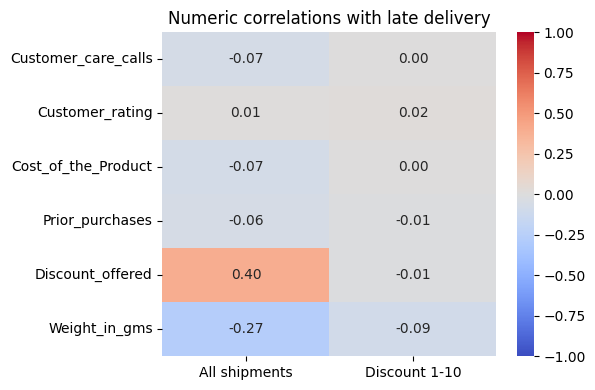

In [34]:
numeric_fields = [
    "Customer_care_calls", "Customer_rating", "Cost_of_the_Product",
    "Prior_purchases", "Discount_offered", "Weight_in_gms"
]
correlation_table = pd.DataFrame({
    "All shipments": df_clean[numeric_fields + ["Delayed"]].corr()["Delayed"].drop("Delayed"),
    "Discount 1-10": normal_orders[numeric_fields + ["Delayed"]].corr()["Delayed"].drop("Delayed")
})
display(correlation_table.round(3))

plt.figure(figsize=(6, 4))
sns.heatmap(correlation_table, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Numeric correlations with late delivery")
plt.tight_layout()
plt.show()

## Check Uncertainty and Review Coverage

A rate from a small group is less precise than a rate from a large group. We add 95% Wilson confidence intervals for the observed late rate and recall. These intervals assume independent shipments and describe sampling uncertainty; they do not account for choosing rules after exploring this file.

We also try the union of the light-weight/few-purchases group and Weight Q2. This flags an order when either condition holds. We count each order once and check how much extra review work it creates. This added rule is exploratory.

Baseline late rate and 95% interval: 46.89 (np.float64(45.82), np.float64(47.96))


,Rule,Flagged,Late,False alarms,Review share (%),Late rate (%),Rate CI low,Rate CI high,Recall (%),Recall CI low,Recall CI high
0,Light + few purchases,200,165,35,2.39,82.50,76.64,87.14,4.21,3.63,4.89
1,Score 2 or 3,654,395,259,7.83,60.40,56.60,64.07,10.09,9.18,11.07
2,Weight Q2,1062,664,398,12.72,62.52,59.57,65.38,16.96,15.81,18.16
3,High importance,677,345,332,8.11,50.96,47.20,54.71,8.81,7.96,9.74
4,Light + few OR Weight Q2,1262,829,433,15.11,65.69,63.03,68.26,21.17,19.92,22.48


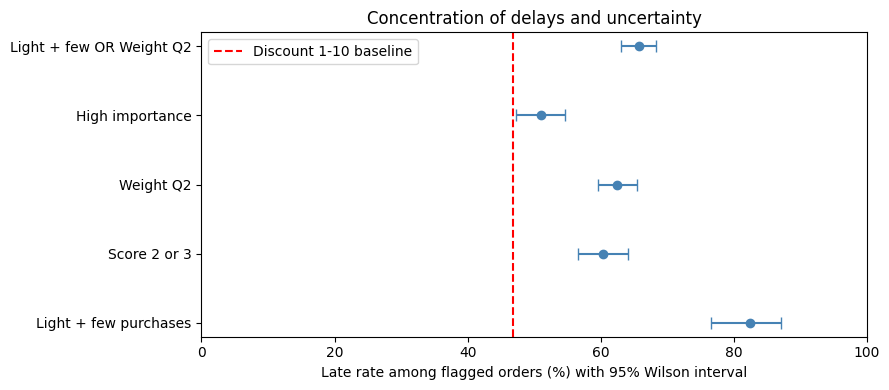

In [35]:
def wilson_interval(successes, total):
    """95% interval for a proportion; return percentage limits."""
    if total == 0:
        return np.nan, np.nan
    z = stats.norm.ppf(0.975)
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    margin = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return 100 * (center - margin), 100 * (center + margin)

review_groups = candidate_groups.copy()
review_groups["Light + few OR Weight Q2"] = light_few | (weight_quartile == "Q2")
review_rows = []
for name, mask in review_groups.items():
    selected = mask & normal_discount
    count = int(selected.sum())
    late = int(df_clean.loc[selected, "Delayed"].sum())
    rate_low, rate_high = wilson_interval(late, count)
    recall_low, recall_high = wilson_interval(late, int(normal_late))
    review_rows.append([name, count, late, count - late,
                        100 * count / len(normal_orders), 100 * late / count,
                        rate_low, rate_high, 100 * late / normal_late,
                        recall_low, recall_high])
review_comparison = pd.DataFrame(review_rows, columns=[
    "Rule", "Flagged", "Late", "False alarms", "Review share (%)",
    "Late rate (%)", "Rate CI low", "Rate CI high", "Recall (%)",
    "Recall CI low", "Recall CI high"])
print("Baseline late rate and 95% interval:", round(normal_rate, 2),
      tuple(round(x, 2) for x in wilson_interval(int(normal_late), len(normal_orders))))
display(review_comparison.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(review_comparison))
rates = review_comparison["Late rate (%)"]
ax.errorbar(rates, positions,
            xerr=[rates - review_comparison["Rate CI low"], review_comparison["Rate CI high"] - rates],
            fmt="o", capsize=4, color="steelblue")
ax.set_yticks(positions, review_comparison["Rule"])
ax.axvline(normal_rate, color="red", linestyle="--", label="Discount 1-10 baseline")
ax.set_xlim(0, 100)
ax.set_xlabel("Late rate among flagged orders (%) with 95% Wilson interval")
ax.set_title("Concentration of delays and uncertainty")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation of the broader rule
The union flags 1,262 orders (15.11% of the discount 1-10 subset), finds 829 late orders, and produces 433 false alarms. Precision is 65.69% and recall is 21.17%. Compared with the narrow rule, it adds 664 late orders and 398 false alarms. It still misses 78.83% of late orders in this subset. Review cost and an effective intervention matter before recommending it. The observed precision interval is 63.03-68.26%; this does not guarantee future performance.

## Account for Multiple Statistical Comparisons

Testing many groups increases the chance of finding a small p-value by chance. We collect the 18 chi-square comparisons used in the main analysis into one family and apply the Holm correction at 0.05. The table keeps both raw and adjusted p-values, effect sizes, and minimum expected counts. This correction applies to this listed family; it does not undo exploratory threshold selection or establish causation.

In [36]:
full_factors = {
    "Gender": df_clean["Gender"],
    "Shipment mode": df_clean["Mode_of_Shipment"],
    "Warehouse": df_clean["Warehouse_block"],
    "Mode and warehouse": combined_group,
    "Care calls": df_clean["Customer_care_calls"],
    "Rating": df_clean["Customer_rating"],
    "Prior purchases": df_clean["Prior_purchases"],
    "Cost quartile": cost_quartile,
    "Importance": df_clean["Product_importance"],
    "Discount above 10": df_clean["Discount_offered"] > 10,
    "Weight quartile": weight_quartile,
}
restricted_factors = {name: full_factors[name] for name in
                      ["Care calls", "Rating", "Prior purchases", "Cost quartile", "Importance", "Weight quartile"]}
restricted_factors["Discount values 1-10"] = df_clean["Discount_offered"]
test_rows = []
for population, data, factors in [("All shipments", df_clean, full_factors),
                                  ("Discount 1-10", normal_orders, restricted_factors)]:
    for name, factor in factors.items():
        table = pd.crosstab(factor.loc[data.index], data["Delayed"])
        chi, raw_p, degrees, expected = stats.chi2_contingency(table)
        v = np.sqrt(chi / (len(data) * min(table.shape[0] - 1, table.shape[1] - 1)))
        test_rows.append([population, name, raw_p, v, expected.min()])
adjusted_tests = pd.DataFrame(test_rows, columns=["Population", "Factor", "Raw p", "Cramers V", "Minimum expected count"])
# Holm: sort p-values, multiply by the remaining number of tests,
# then keep adjusted values nondecreasing and no larger than 1.
order = np.argsort(adjusted_tests["Raw p"].to_numpy())
sorted_p = adjusted_tests["Raw p"].to_numpy()[order]
adjusted_sorted = np.minimum(1, np.maximum.accumulate(sorted_p * np.arange(len(sorted_p), 0, -1)))
adjusted = np.empty(len(sorted_p))
adjusted[order] = adjusted_sorted
adjusted_tests["Holm p"] = adjusted
adjusted_tests["Below 0.05 after Holm"] = adjusted_tests["Holm p"] < 0.05
display(adjusted_tests)
print("Comparisons in this family:", len(adjusted_tests))
print("All expected counts at least 5:", bool((adjusted_tests["Minimum expected count"] >= 5).all()))

,Population,Factor,Raw p,Cramers V,Minimum expected count,Holm p,Below 0.05 after Holm
0,All shipments,Gender,6.367032e-01,0.004504,2199.649423,1.000000e+00,False
1,All shipments,Shipment mode,6.895488e-01,0.008221,709.824530,1.000000e+00,False
2,All shipments,Warehouse,8.959524e-01,0.009952,739.266115,1.000000e+00,False
3,All shipments,Mode and warehouse,9.978033e-01,0.017835,117.766342,1.000000e+00,False
4,All shipments,Care calls,1.841150e-10,0.070245,99.214110,2.393495e-09,True
5,All shipments,Rating,5.249236e-01,0.017057,873.164833,1.000000e+00,False
6,All shipments,Prior purchases,4.464597e-24,0.106998,51.623602,6.696896e-23,True
7,All shipments,Cost quartile,4.046985e-11,0.068352,1086.918811,5.665779e-10,True
8,All shipments,Importance,2.230383e-03,0.033320,382.337303,2.676460e-02,True
9,All shipments,Discount above 10,0.000000e+00,0.462618,1067.559960,0.000000e+00,True


Comparisons in this family: 18
All expected counts at least 5: True


### What the correction changes
Interpret the adjusted p-values alongside effect sizes. Weight remains the main pattern to investigate within discounts 1-10. The prior-purchase p-value within discounts 1-10 changes from 0.017 to 0.190 after Holm correction, so it no longer falls below 0.05. Weight remains below 0.001 after correction. A non-significant test does not establish that two groups are identical.

## What Would Validate an Operational Recommendation

The present file has already been explored, so another split of it cannot become an untouched future test. Freeze a rule before collecting new orders; record when its inputs become available; evaluate precision, recall, and workload on those orders. Then compare an intervention with a suitable control group. Measure late-rate changes, review cost, and false alarms. Dates, routes, carriers, and interaction timestamps must come from the company; they cannot be recovered from this CSV.

## Findings and Practical Next Steps

We started with 10,999 shipments; 6,563 are marked late. No shipment mode, warehouse, or mode-and-warehouse pair clearly stands out. The customer measures are weak once we leave out the unusual high-discount group. Cost and importance also add little in that comparison. Weight Q2 still has a higher late rate across all three shipping methods.

The discount result needs a data check: every value above 10 is paired with a late delivery, and we do not know why. Before a company uses any warning rule, it should record order and dispatch dates, promised and actual arrival, route, carrier, and when calls and ratings happened. It can then test a rule on later orders and measure whether its response reduces delays.

Our analysis points to what to investigate next. It does not establish a cause or prove a fix.

The added union rule shows the cost of covering more delays, and the confidence intervals show uncertainty in observed rates. Holm-adjusted results reduce the risk of over-interpreting isolated p-values. These additions strengthen the exploratory analysis; future-order validation and an intervention study remain necessary.